# Selected covariates and residual load

Relationships between residual load and the selected observed load, weather, and Germany/Luxembourg day-ahead electricity price are examined over 2023–2024. Their distributions and temporal patterns provide context for interpreting their association with residual load.

Observed load and weather become available after observation and publication. Day-ahead prices are available after publication for their delivery period, so their use depends on the forecast origin. Same-time associations can reflect shared seasonality and market conditions.

References: [FPP3 time-series graphics](https://otexts.com/fpp3/graphics.html) and [predictor availability](https://otexts.com/fpp3/regression.html).

## 1. Setup

In [1]:
from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/experiments/chronos2.yaml').exists())
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'notebooks' / 'eda' / '03_covariates')
CONFIG_PATH = PROJECT_ROOT / 'configs/experiments/chronos2.yaml'
config = yaml.safe_load(CONFIG_PATH.read_text(encoding='utf-8'))
data_cfg = config['data']
TARGET = 'Residual load [MWh]'
YEARS = [2023, 2024]
COLORS = ['#0072B2', '#D55E00']
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=COLORS)
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.options.display.float_format = '{:,.2f}'.format


## 2. Selected covariates
### 2.1 Model covariates

In [2]:
experiment_paths = sorted((PROJECT_ROOT / 'configs/experiments').glob('*.yaml'))
selected_historical = []
for path in experiment_paths:
    cfg = yaml.safe_load(path.read_text(encoding='utf-8'))
    settings = cfg.get('data', {})
    groups = settings.get('covariates', {})
    if isinstance(groups, dict):
        selected_historical.extend(groups.get('historical', []))
    elif groups:
        selected_historical.extend(groups)
    selected_historical.extend(settings.get('historical_weather', []))
selected_historical = list(dict.fromkeys(selected_historical))
PRICE = 'Germany/Luxembourg [€/MWh]'
selected_historical.append(PRICE)
print('Selected source covariates:', *selected_historical, sep='\n- ')


Selected source covariates:
- grid load [MWh]
- Grid load incl. hydro pumped storage [MWh]
- Hydro pumped storage [MWh]
- temperature_2m (°C)
- wind_speed_10m (km/h)
- dew_point_2m (°C)
- relative_humidity_2m (%)
- precipitation (mm)
- shortwave_radiation (W/m²)
- Germany/Luxembourg [€/MWh]


### 2.2 Observation coverage

In [3]:
source = data_cfg['sources']['consumption']
raw = pd.read_csv(PROJECT_ROOT / source['development'])
dates = pd.to_datetime(raw[source['timestamp_column']], format='%b %d, %Y %I:%M %p', errors='raise')
utc = dates.dt.tz_localize(source['timezone'], ambiguous='infer').dt.tz_convert('UTC')
assert utc.notna().all() and utc.is_monotonic_increasing and not utc.duplicated().any()
values = pd.to_numeric(raw[TARGET], errors='coerce').replace([np.inf, -np.inf], np.nan)
df = pd.DataFrame({'target': values.to_numpy()}, index=pd.DatetimeIndex(utc, name='timestamp_utc'))
local = df.index.tz_convert('Europe/Berlin')
df = df.loc[local.year.isin(YEARS)].copy()
local = df.index.tz_convert('Europe/Berlin')
df['year'] = local.year
print(f'Source: {source["development"]}')
print(f'Target: {TARGET} | {len(df):,} intervals | Berlin years: {YEARS}')

consumption_columns = [name for name in selected_historical if name in raw.columns]
for column in consumption_columns:
    observed = pd.Series(pd.to_numeric(raw[column], errors='coerce').to_numpy(), index=pd.DatetimeIndex(utc))
    df[column] = observed.reindex(df.index)
weather_source = data_cfg['sources']['weather']
weather = pd.read_csv(PROJECT_ROOT / weather_source['development'])
weather_dates = pd.to_datetime(weather[weather_source['timestamp_column']], format='%Y-%m-%d %H:%M:%S', errors='raise')
weather_utc = weather_dates.dt.tz_localize(weather_source['timezone']).dt.tz_convert('UTC')
assert weather_utc.notna().all() and not weather_utc.duplicated().any() and weather_utc.is_monotonic_increasing
weather_columns = [name for name in selected_historical if name in weather.columns]
weather_values = weather[weather_columns].apply(pd.to_numeric, errors='coerce')
weather_values.index = pd.DatetimeIndex(weather_utc)
unmatched_weather = int((~df.index.isin(weather_values.index)).sum())
df = df.join(weather_values, validate='one_to_one')
# Align Day-Ahead Prices
prices = pd.read_csv(PROJECT_ROOT / 'Dataset/raw/csv/Day-ahead_prices_2023_2024_Quarterhour.csv')
price_dates = pd.to_datetime(prices['Start date'], format='%b %d, %Y %I:%M %p', errors='raise')
price_utc = price_dates.dt.tz_localize('Europe/Berlin', ambiguous='infer').dt.tz_convert('UTC')
assert price_utc.notna().all() and price_utc.is_monotonic_increasing and not price_utc.duplicated().any()
price_values = pd.Series(pd.to_numeric(prices[PRICE], errors='coerce').to_numpy(), index=pd.DatetimeIndex(price_utc))
unmatched_price = int((~df.index.isin(price_values.index)).sum())
df[PRICE] = price_values.reindex(df.index)
print(f'Price rows unmatched: {unmatched_price:,}. Prices retain their source units of €/MWh.')

df[selected_historical] = df[selected_historical].replace([np.inf, -np.inf], np.nan)
assert not (set(selected_historical) - set(df.columns)), 'A selected covariate has no raw source.'
print(f'Weather rows unmatched: {unmatched_weather:,}. Raw missing values remain visible.')
print('The source weather offset is fixed UTC+2. Consumption uses Europe/Berlin.')

Source: Dataset/raw/csv/Actual_consumption_2023_2024_Quarterhour.csv
Target: Residual load [MWh] | 70,176 intervals | Berlin years: [2023, 2024]
Price rows unmatched: 0. Prices retain their source units of €/MWh.
Weather rows unmatched: 4. Raw missing values remain visible.
The source weather offset is fixed UTC+2. Consumption uses Europe/Berlin.


### Observations

The selected source variables cover three related load measurements, six local weather measurements, and Germany/Luxembourg day-ahead price. The load and residual-load series describe the TransnetBW control area, while the weather describes the Stuttgart location and price covers the wider bidding zone. These differences in geographic coverage matter when interpreting weak or noisy relationships.

## 3. Basic checks
### 3.1 Missing values and unique values

In [4]:
display(df[selected_historical].agg(['count', 'nunique']).T.assign(missing=df[selected_historical].isna().sum()))
print('Counts apply to aligned 15-minute observations. No imputation is applied.')

,count,nunique,missing
grid load [MWh],70176,5977,0
Grid load incl. hydro pumped storage [MWh],70176,6004,0
Hydro pumped storage [MWh],70176,1766,0
temperature_2m (°C),70172,437,4
wind_speed_10m (km/h),70172,303,4
dew_point_2m (°C),70172,332,4
relative_humidity_2m (%),70172,87,4
precipitation (mm),70172,50,4
shortwave_radiation (W/m²),70172,922,4
Germany/Luxembourg [€/MWh],70176,9844,0


Counts apply to aligned 15-minute observations. No imputation is applied.


### 3.2 Timestamp alignment

In [5]:
expected = pd.date_range(df.index.min(), df.index.max(), freq='15min')
print(f'Consumption missing intervals: {len(expected.difference(df.index))}')
print(f'Duplicate consumption UTC timestamps: {df.index.duplicated().sum()}')
print(f'Duplicate weather UTC timestamps: {weather_utc.duplicated().sum()}')
print(f'Unmatched weather intervals: {unmatched_weather}')
assert len(df) == len(raw)
assert len(expected.difference(df.index)) == 0

Consumption missing intervals: 0
Duplicate consumption UTC timestamps: 0
Duplicate weather UTC timestamps: 0
Unmatched weather intervals: 4


### 3.3 Load-column relationship

In [6]:
a = 'Grid load incl. hydro pumped storage [MWh]'
b = 'grid load [MWh]'
c = 'Hydro pumped storage [MWh]'
if {a, b, c}.issubset(selected_historical):
    difference = (df[a] - df[b] - df[c]).dropna()
    print(f'Maximum absolute difference between inclusive load and grid load plus pumping: {difference.abs().max():.4f} MWh.')
    print('These selected measurements can contain overlapping information. All are retained in this descriptive EDA.')

Maximum absolute difference between inclusive load and grid load plus pumping: 0.0000 MWh.
These selected measurements can contain overlapping information. All are retained in this descriptive EDA.


### Observations

Load and price observations cover all 70,176 development intervals. Weather is missing only for the final four intervals of 2024 after timezone alignment. These are boundary gaps in coverage and provide no evidence of a recurring missing-data pattern.

The inclusive load column equals grid load plus the pumped-storage column throughout the dataset. These three measurements therefore contain an exact arithmetic dependency, which is important when interpreting their correlations and their separate contributions to a model.

## 4. Source covariates

Load measurements describe electricity-system conditions, while weather variables provide context for demand and renewable generation. Day-ahead price adds the market context for electricity delivery. Daily averages reveal slower changes in these measurements.

Scatterplots show up to 4,000 complete observation pairs, and binned averages use all complete pairs. These views help identify nonlinear relationships that a single correlation coefficient can miss.

### 4.1 Grid load
#### Time plot

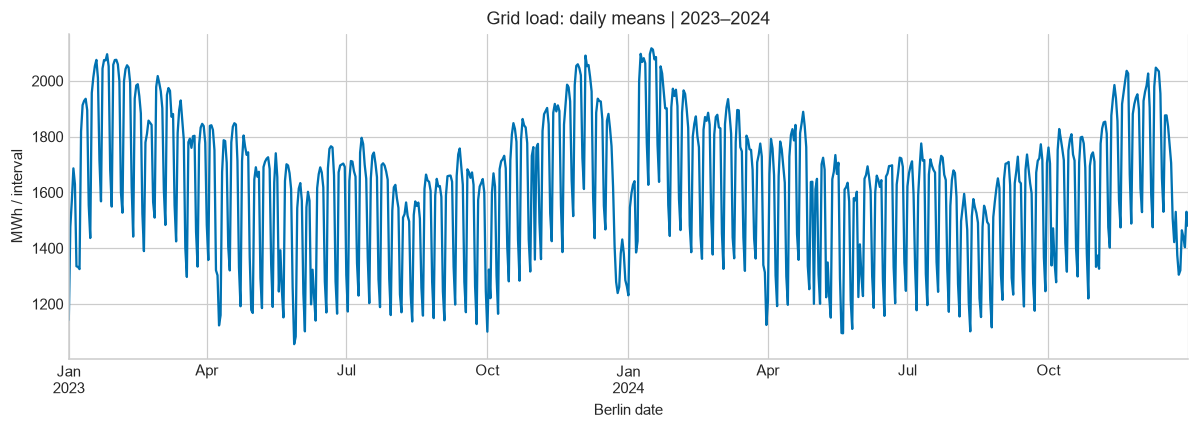

In [7]:
column = "grid load [MWh]"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Grid load: daily means | 2023–2024', xlabel='Berlin date', ylabel='MWh / interval')
fig.tight_layout()
fig.savefig('historical_covariates_grid_load_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

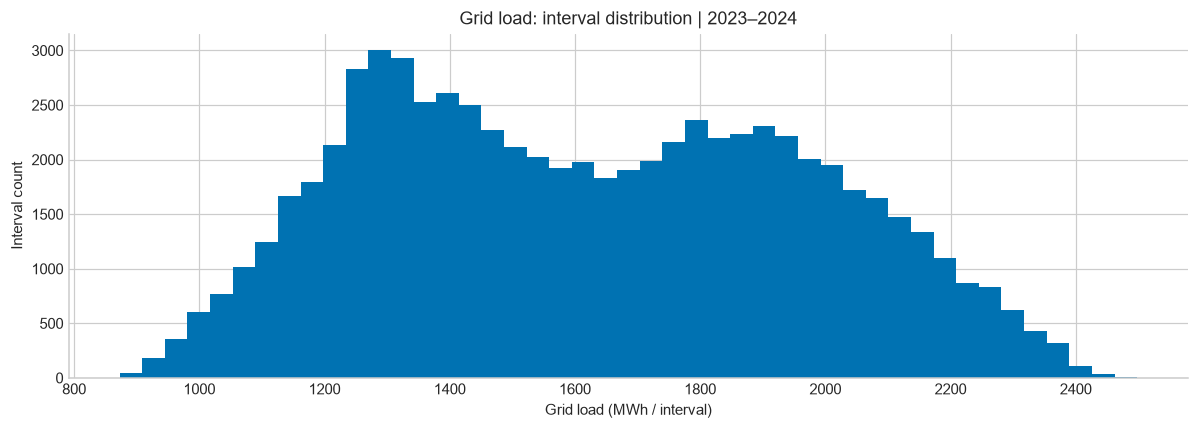

In [8]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Grid load: interval distribution | 2023–2024', xlabel='Grid load (MWh / interval)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_grid_load_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

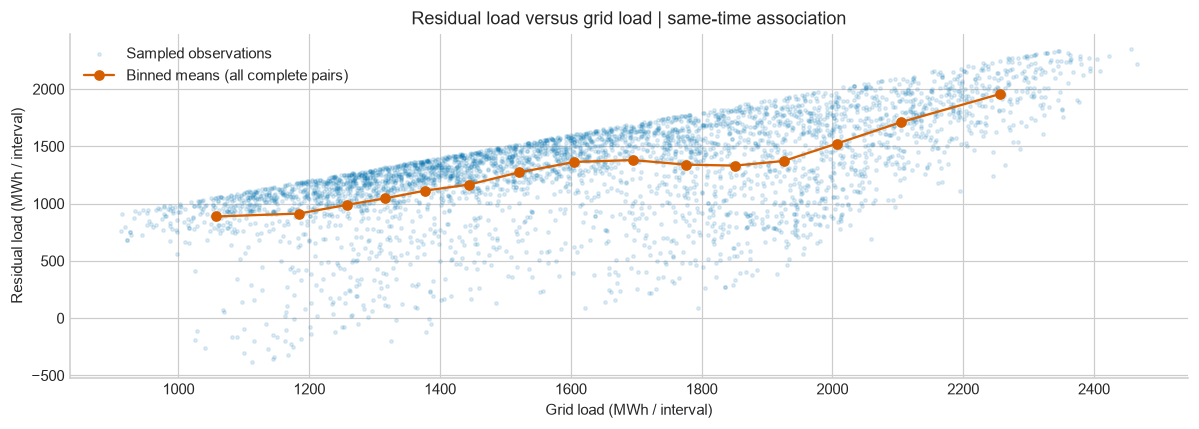

Complete pairs: 70,175. Pearson correlation: 0.627.


In [9]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus grid load | same-time association', xlabel='Grid load (MWh / interval)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_grid_load_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Grid load shows a strong weekly rhythm, higher winter levels, and a pronounced drop around Christmas and New Year. Its histogram has two broad concentrations around 1,300 and 1,850 MWh per interval, consistent with a mixture of lower- and higher-load operating periods.

Residual load generally rises with grid load, with correlation 0.627. The scatter has a clear upper boundary and a wide spread below it, as expected when wind and solar generation reduce residual load by different amounts. The binned relationship flattens around 1,700–1,900 MWh before rising again, so a single straight-line relationship misses some of its shape.

### 4.2 Grid load including pumped storage
#### Time plot

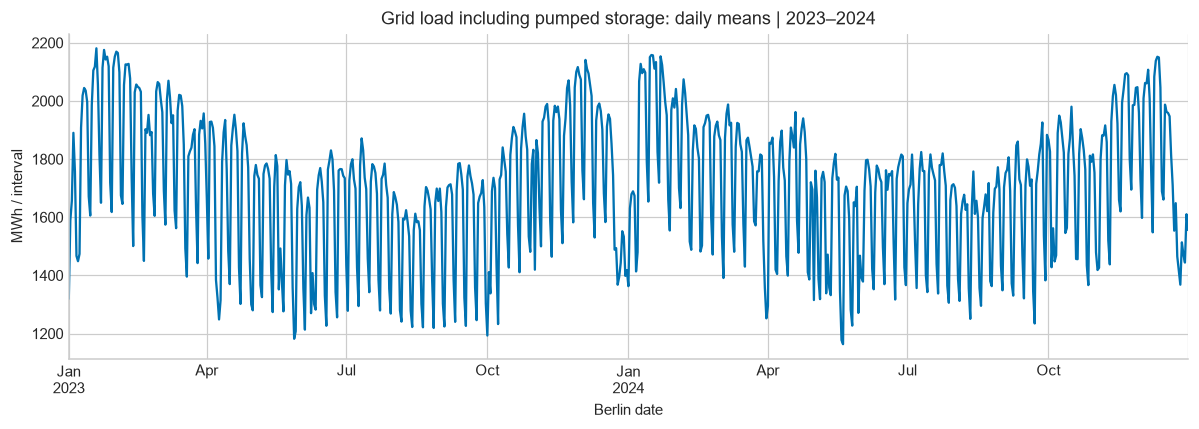

In [10]:
column = "Grid load incl. hydro pumped storage [MWh]"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Grid load including pumped storage: daily means | 2023–2024', xlabel='Berlin date', ylabel='MWh / interval')
fig.tight_layout()
fig.savefig('historical_covariates_grid_load_including_pumped_storage_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

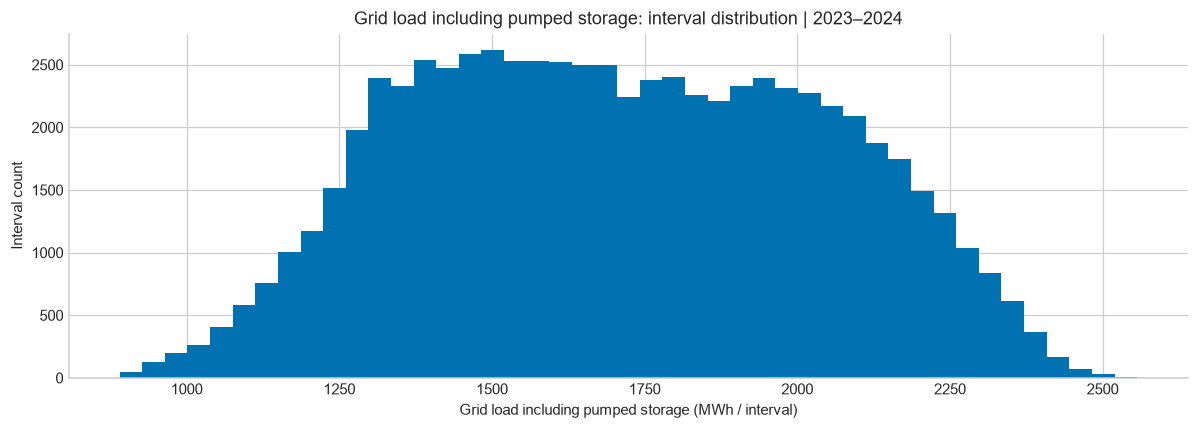

In [11]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Grid load including pumped storage: interval distribution | 2023–2024', xlabel='Grid load including pumped storage (MWh / interval)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_grid_load_including_pumped_storage_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

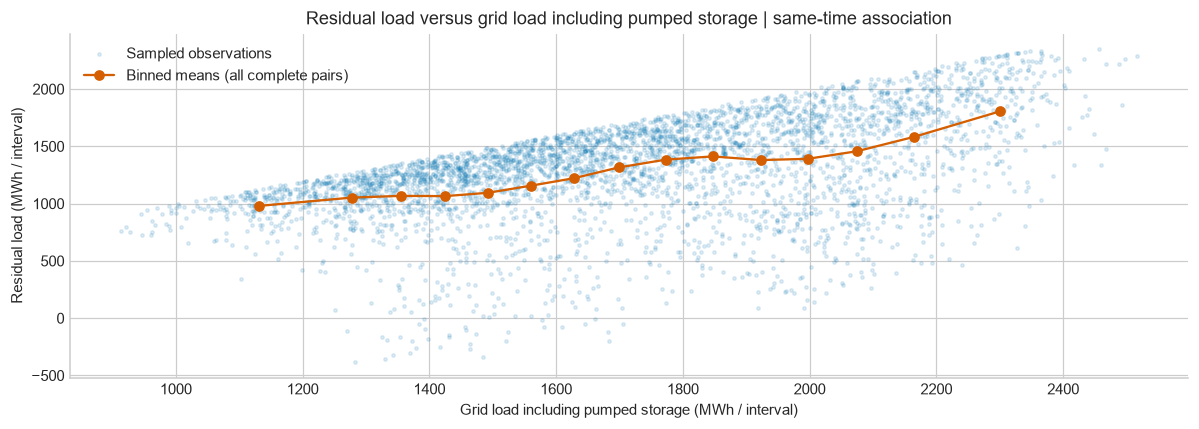

Complete pairs: 70,175. Pearson correlation: 0.495.


In [12]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus grid load including pumped storage | same-time association', xlabel='Grid load including pumped storage (MWh / interval)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_grid_load_including_pumped_storage_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Including pumped storage preserves the winter and weekly pattern while shifting the load distribution upward and making its centre broader. The binned residual-load relationship rises overall but is relatively flat across parts of the middle range.

Its correlation with residual load is 0.495, below the 0.627 correlation for grid load alone. The arithmetic dependency among the three load columns helps explain this difference: adding the pumped-storage measure changes the relationship with residual load.

### 4.3 Pumped storage
#### Time plot

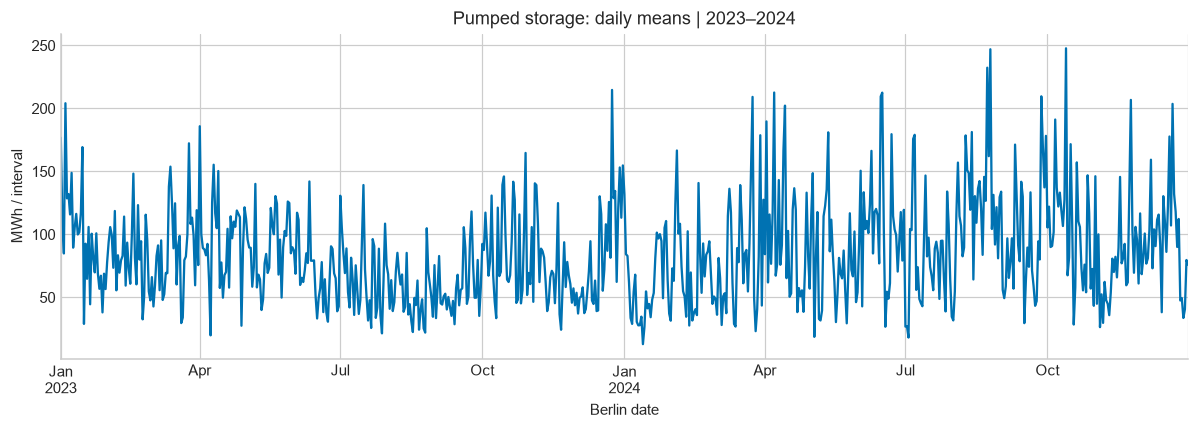

In [13]:
column = "Hydro pumped storage [MWh]"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Pumped storage: daily means | 2023–2024', xlabel='Berlin date', ylabel='MWh / interval')
fig.tight_layout()
fig.savefig('historical_covariates_pumped_storage_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

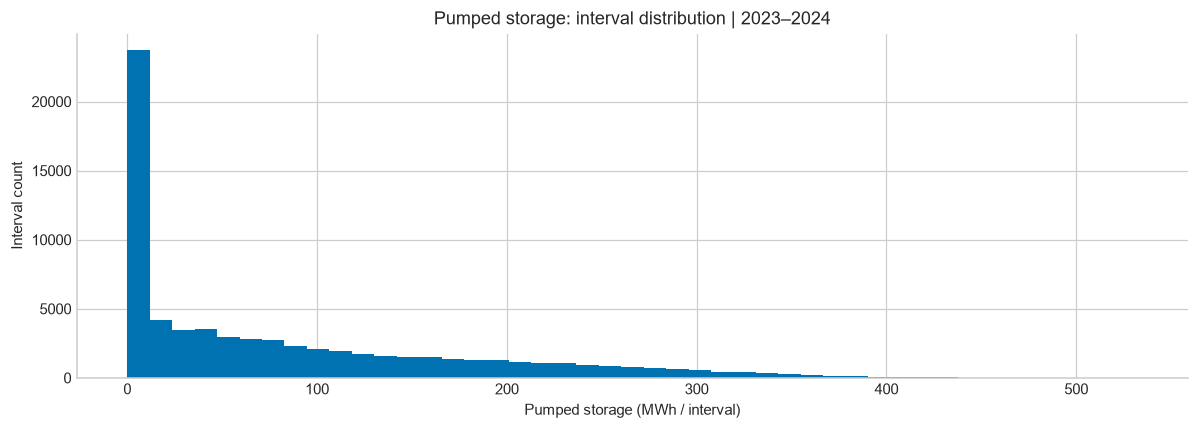

In [14]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Pumped storage: interval distribution | 2023–2024', xlabel='Pumped storage (MWh / interval)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_pumped_storage_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

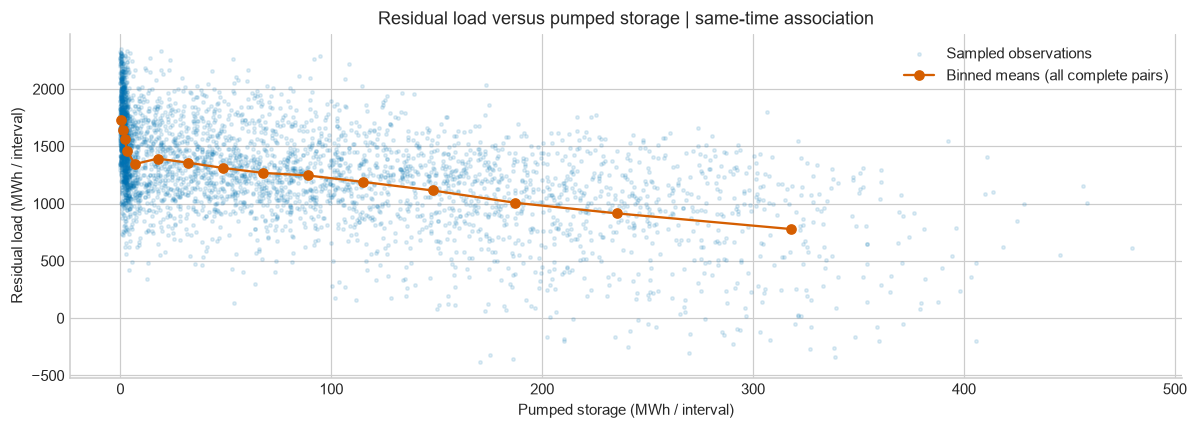

Complete pairs: 70,175. Pearson correlation: -0.554.


In [15]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus pumped storage | same-time association', xlabel='Pumped storage (MWh / interval)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_pumped_storage_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

The pumped-storage measure has a strongly right-skewed distribution, with many very small values and occasional intervals above 400 MWh. Its daily average is more variable during much of 2024, and its yearly mean rises from about 79 to 91 MWh per interval.

Higher values tend to coincide with lower residual load, giving correlation −0.554. The binned curve declines sharply near the lowest values and then more gradually. This association may reflect how storage operation responds to wider system conditions. The scatter alone does not identify a causal effect or resolve the operating mode.

### 4.4 Temperature
#### Time plot

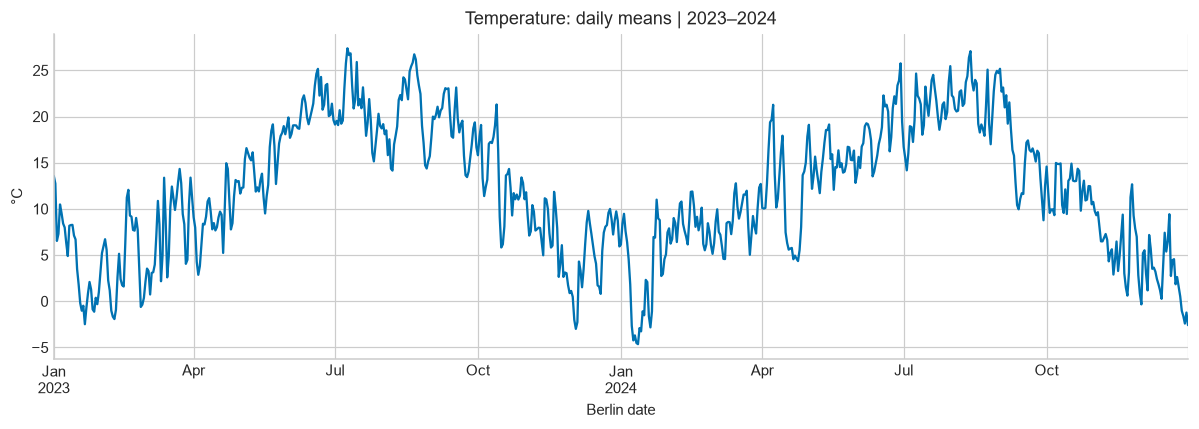

In [16]:
column = "temperature_2m (°C)"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Temperature: daily means | 2023–2024', xlabel='Berlin date', ylabel='°C')
fig.tight_layout()
fig.savefig('historical_covariates_temperature_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

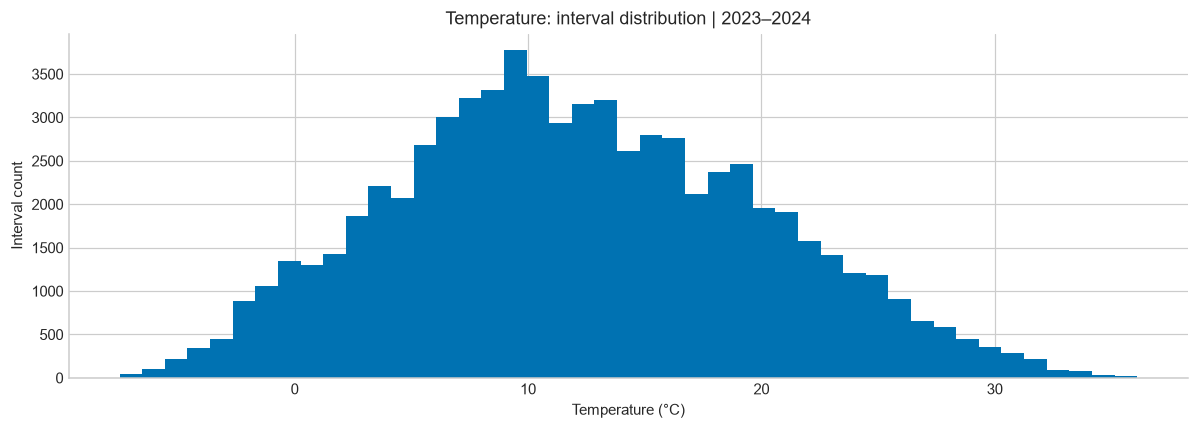

In [17]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Temperature: interval distribution | 2023–2024', xlabel='Temperature (°C)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_temperature_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

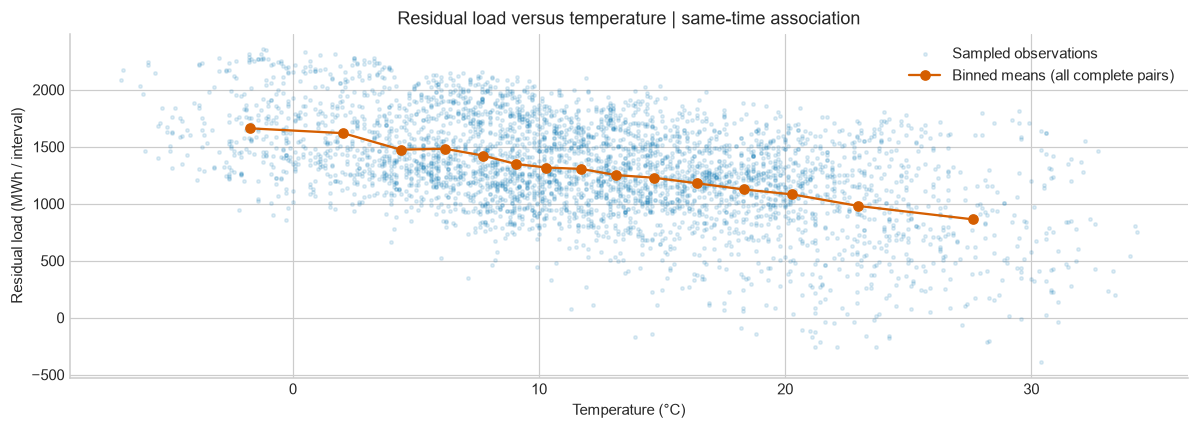

Complete pairs: 70,171. Pearson correlation: -0.499.


In [18]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus temperature | same-time association', xlabel='Temperature (°C)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_temperature_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Temperature follows a clear annual cycle, with a pronounced cold spell in January 2024 and warm periods in both summers. Most interval temperatures lie between roughly 0°C and 25°C.

Mean residual load decreases steadily across the temperature bins, with correlation −0.499. The pooled plot shows no clear high-temperature upturn. Lower winter temperatures coincide with higher seasonal residual load, so the relationship can combine demand effects and seasonal changes in renewable generation. It does not isolate the effect of temperature at a fixed hour and season.

### 4.5 Wind speed
#### Time plot

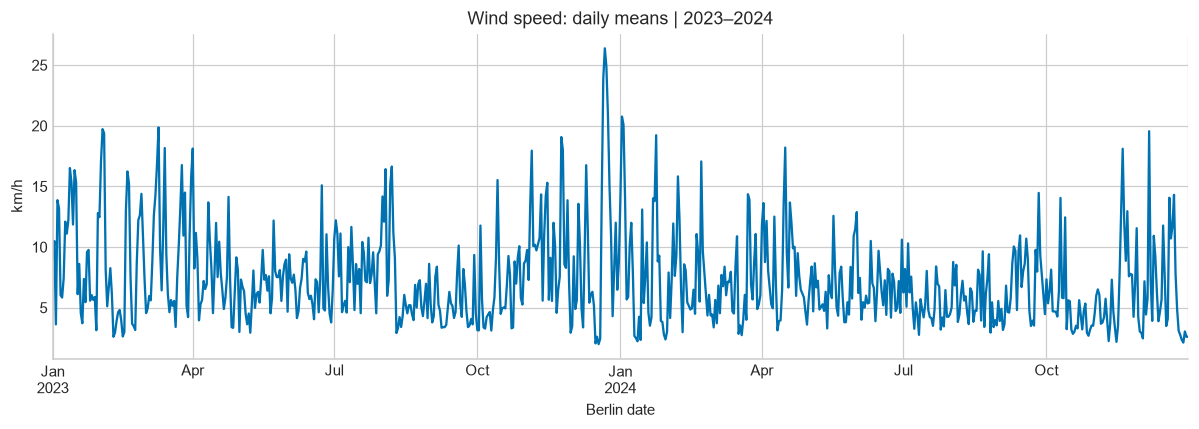

In [19]:
column = "wind_speed_10m (km/h)"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Wind speed: daily means | 2023–2024', xlabel='Berlin date', ylabel='km/h')
fig.tight_layout()
fig.savefig('historical_covariates_wind_speed_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

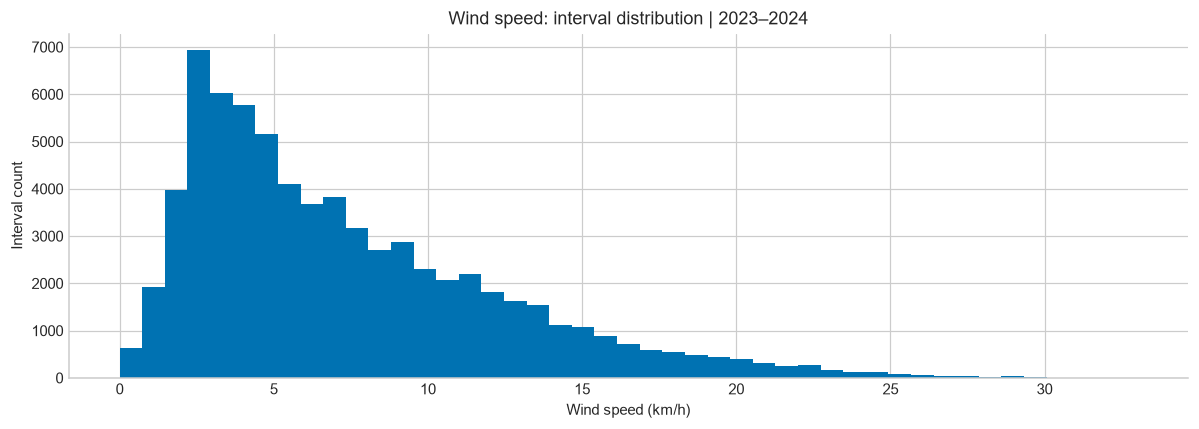

In [20]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Wind speed: interval distribution | 2023–2024', xlabel='Wind speed (km/h)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_wind_speed_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

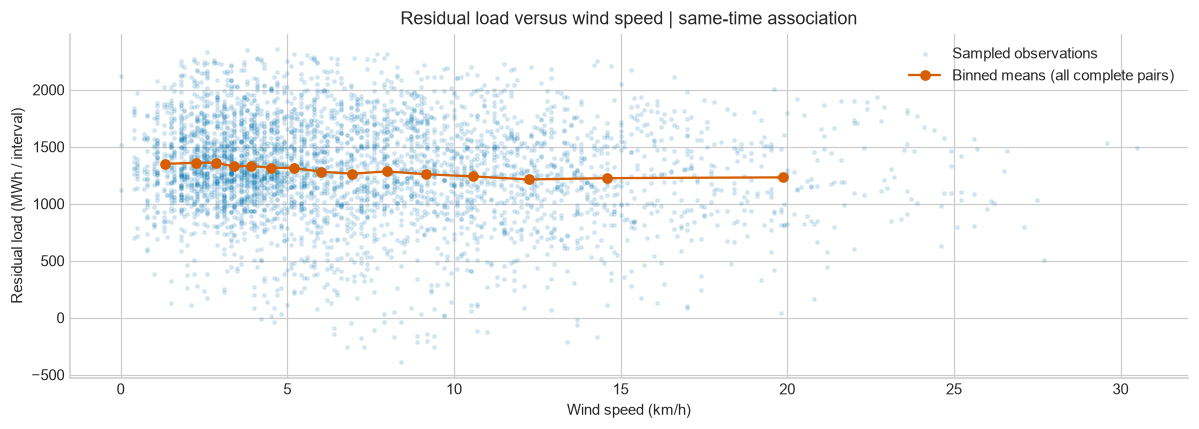

Complete pairs: 70,171. Pearson correlation: -0.099.


In [21]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus wind speed | same-time association', xlabel='Wind speed (km/h)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_wind_speed_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Local wind speed is dominated by short-lived spikes, including a particularly windy period late in 2023. Its distribution is right-skewed, with most observations below 10 km/h and relatively few high-wind intervals.

The relationship with residual load is weak: correlation is −0.099 and the binned means decline only slightly before flattening. This local 10-metre wind measurement provides limited evidence of a strong standalone relationship. Wind conditions at one Stuttgart location may represent regional wind generation imperfectly, so this result does not establish that wind generation is unimportant.

### 4.6 Dew point
#### Time plot

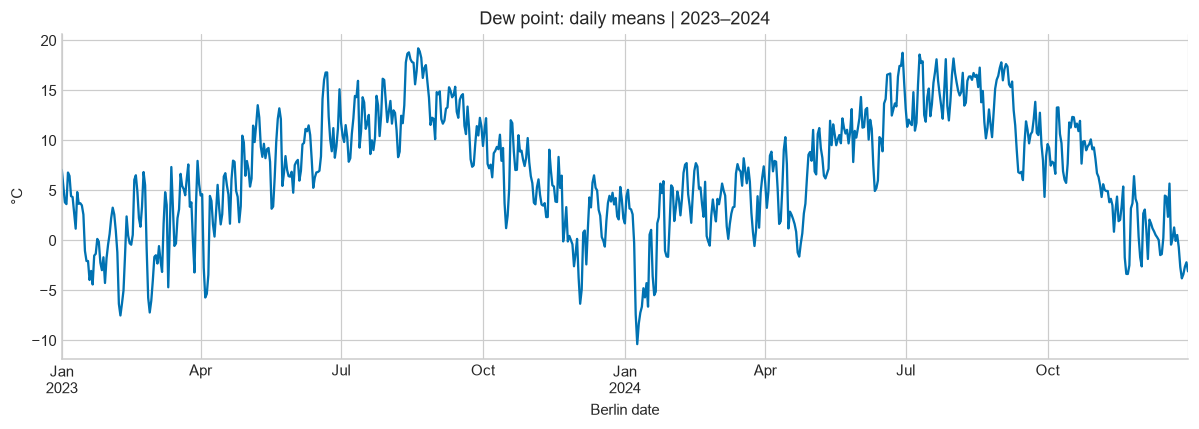

In [22]:
column = "dew_point_2m (°C)"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Dew point: daily means | 2023–2024', xlabel='Berlin date', ylabel='°C')
fig.tight_layout()
fig.savefig('historical_covariates_dew_point_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

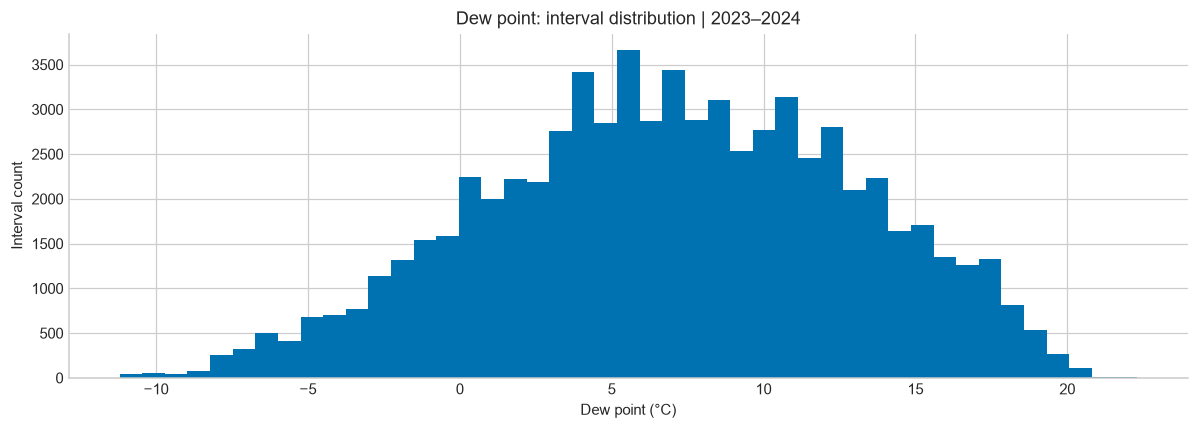

In [23]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Dew point: interval distribution | 2023–2024', xlabel='Dew point (°C)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_dew_point_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

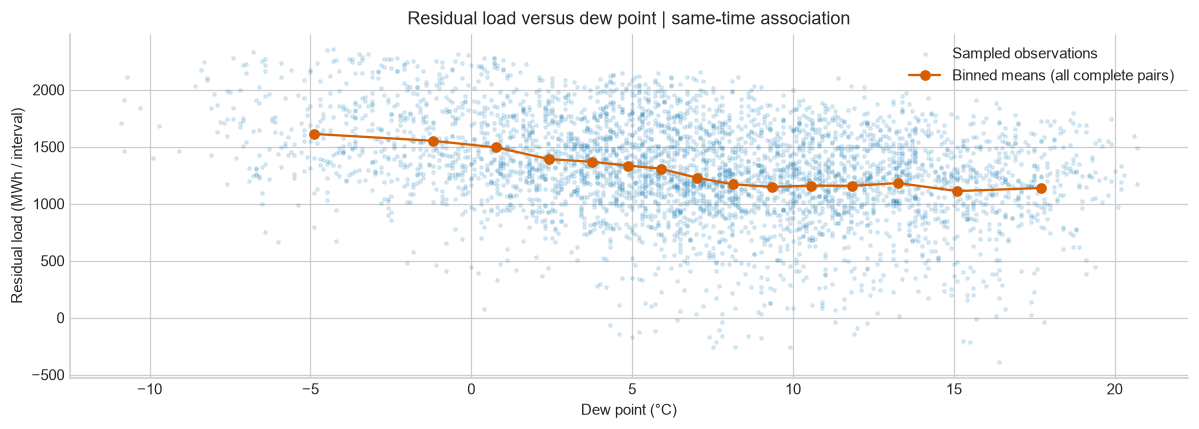

Complete pairs: 70,171. Pearson correlation: -0.344.


In [24]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus dew point | same-time association', xlabel='Dew point (°C)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_dew_point_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Dew point rises through spring and summer and falls in winter, closely resembling the temperature cycle. The cold spell in January 2024 is also visible here.

Residual load decreases across the lower dew-point bins, then the binned relationship flattens at about 9°C and above. Its correlation with residual load is −0.344. Dew point and temperature are strongly correlated with each other at 0.84, so part of their apparent relationship with residual load likely reflects shared seasonal information.

### 4.7 Relative humidity
#### Time plot

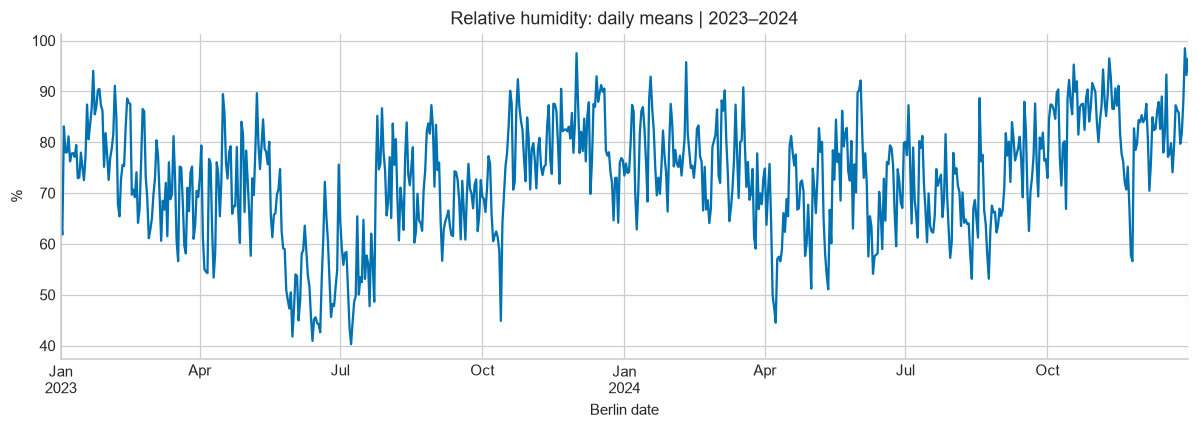

In [25]:
column = "relative_humidity_2m (%)"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Relative humidity: daily means | 2023–2024', xlabel='Berlin date', ylabel='%')
fig.tight_layout()
fig.savefig('historical_covariates_relative_humidity_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

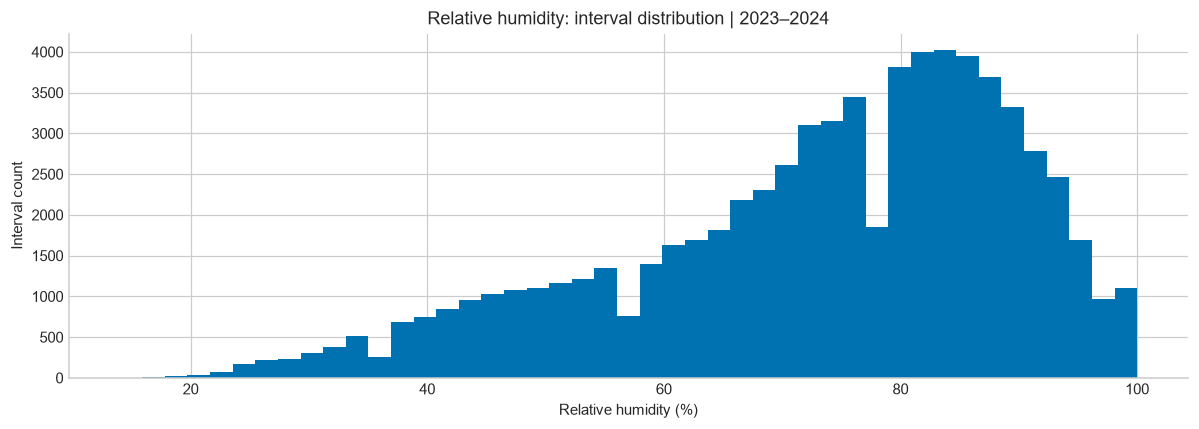

In [26]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Relative humidity: interval distribution | 2023–2024', xlabel='Relative humidity (%)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_relative_humidity_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

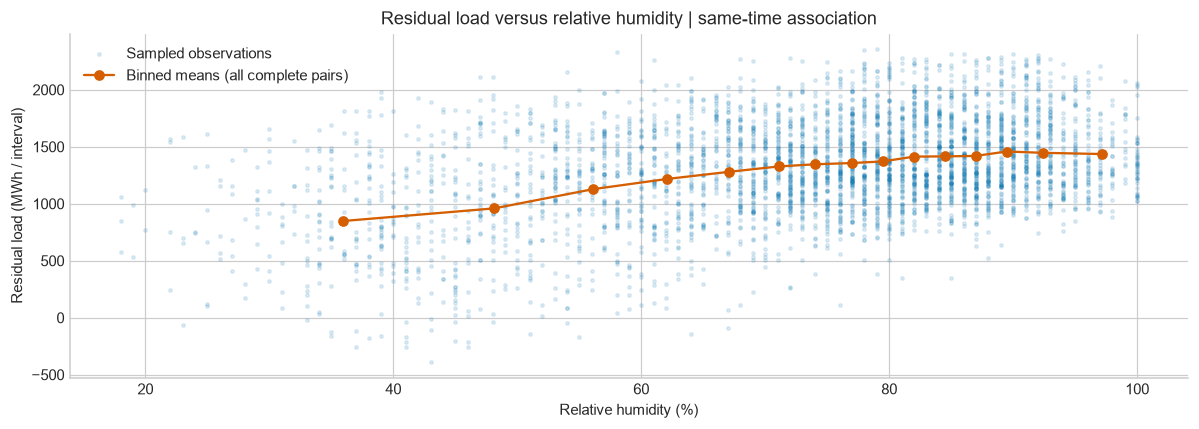

Complete pairs: 70,171. Pearson correlation: 0.403.


In [27]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus relative humidity | same-time association', xlabel='Relative humidity (%)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_relative_humidity_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Relative humidity is usually high, with many observations around 70–90%. Early summer 2023 includes a sustained drier period, while autumn and winter generally have higher humidity.

Residual load rises across the humidity bins and then levels off above roughly 75–80%, with correlation 0.403. Humidity is negatively correlated with radiation at −0.64. The positive target association is therefore consistent with humidity also marking periods with less solar input, alongside seasonal and time-of-day differences. It provides no isolated estimate of a humidity effect.

### 4.8 Precipitation
#### Time plot

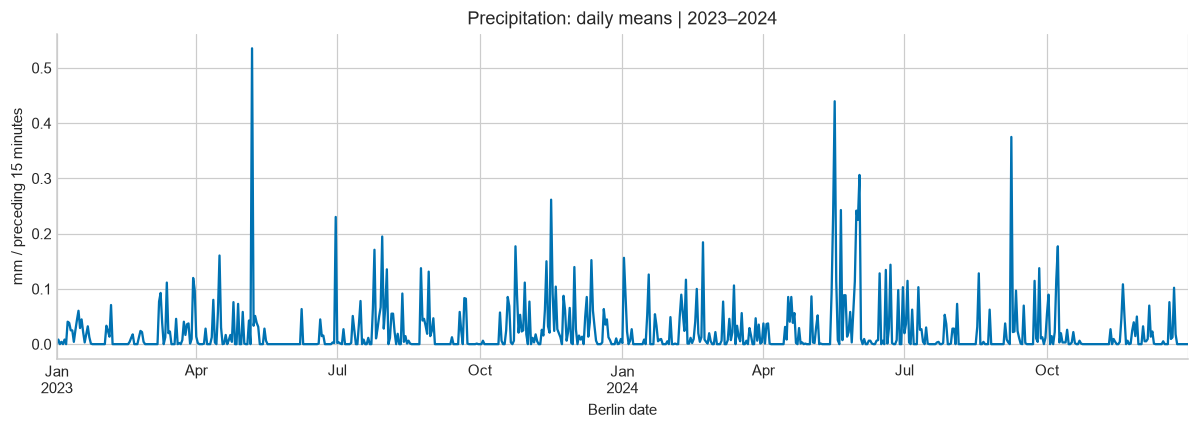

In [28]:
column = "precipitation (mm)"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Precipitation: daily means | 2023–2024', xlabel='Berlin date', ylabel='mm / preceding 15 minutes')
fig.tight_layout()
fig.savefig('historical_covariates_precipitation_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

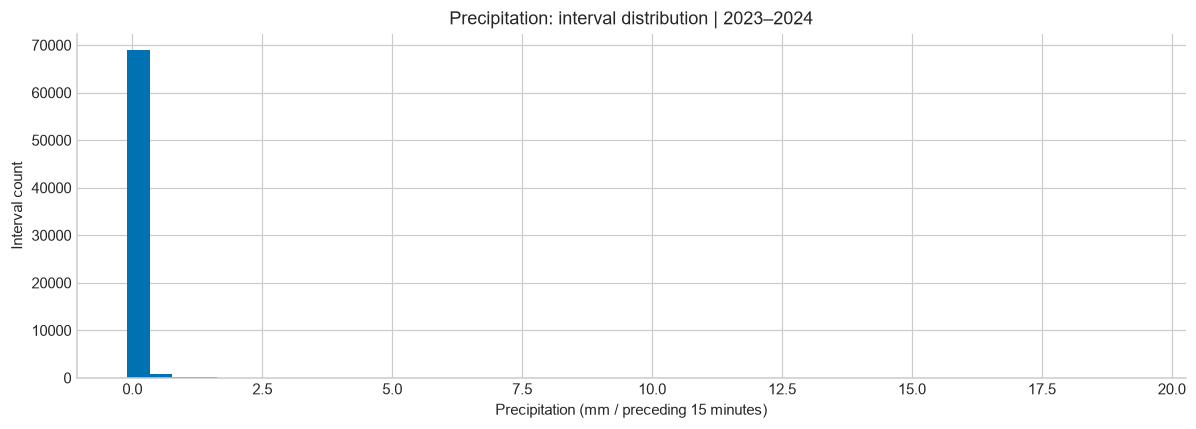

In [29]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Precipitation: interval distribution | 2023–2024', xlabel='Precipitation (mm / preceding 15 minutes)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_precipitation_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

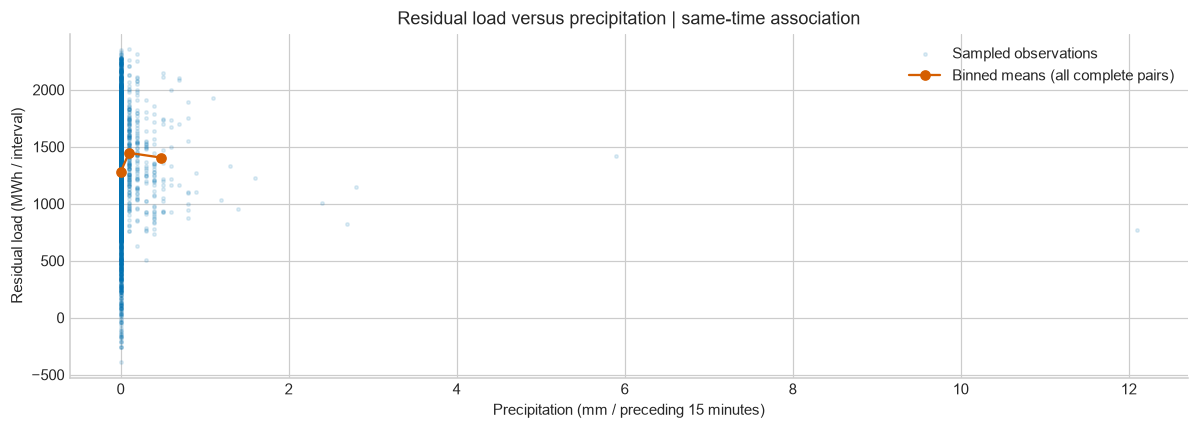

Complete pairs: 70,171. Pearson correlation: 0.026.


In [30]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus precipitation | same-time association', xlabel='Precipitation (mm / preceding 15 minutes)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_precipitation_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Precipitation occurs in intermittent bursts, with isolated large events and long dry stretches. About 91.7% of observed intervals have zero precipitation, so the histogram and scatterplot are dominated by dry conditions.

The target correlation is only 0.026, and the few distinct binned averages show no stable monotonic relationship. The concentration at zero also limits the number of distinct quantile bins, making the curve a coarse description. These plots provide little evidence of a strong standalone same-time relationship, particularly for the sparsely observed heavy-rainfall intervals.

### 4.9 Shortwave radiation
#### Time plot

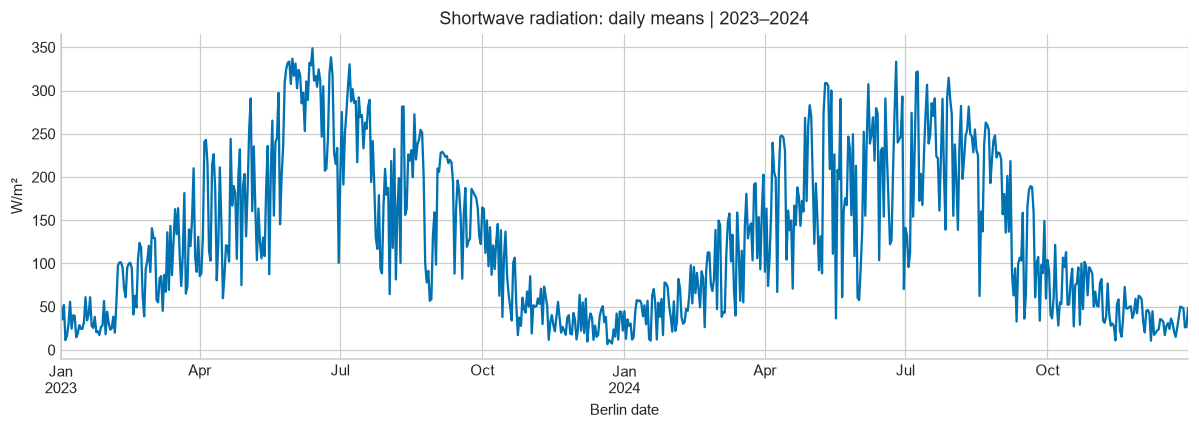

In [31]:
column = "shortwave_radiation (W/m²)"
assert column in selected_historical
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Shortwave radiation: daily means | 2023–2024', xlabel='Berlin date', ylabel='W/m²')
fig.tight_layout()
fig.savefig('historical_covariates_shortwave_radiation_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

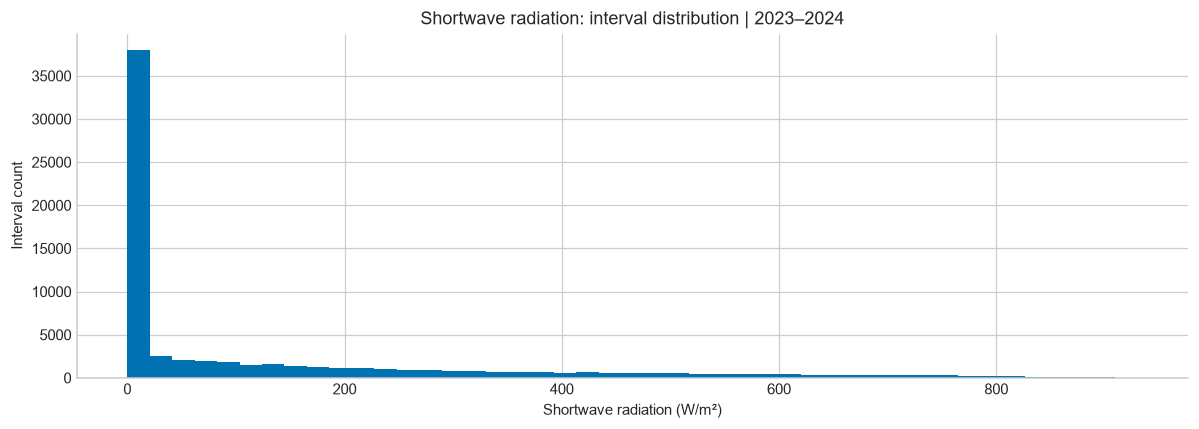

In [32]:
fig, ax = plt.subplots()
ax.hist(df[column].dropna(), bins=45, color=COLORS[0])
ax.set(title='Shortwave radiation: interval distribution | 2023–2024', xlabel='Shortwave radiation (W/m²)', ylabel='Interval count')
fig.tight_layout()
fig.savefig('historical_covariates_shortwave_radiation_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

#### Relationship with residual load

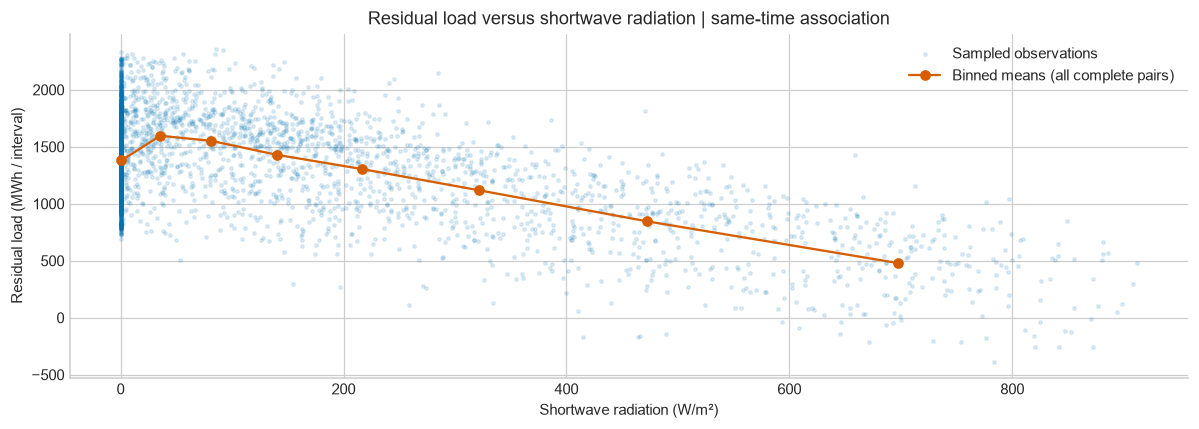

Complete pairs: 70,171. Pearson correlation: -0.590.


In [33]:
pairs = df[[column, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[column], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[column], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[column], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus shortwave radiation | same-time association', xlabel='Shortwave radiation (W/m²)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('historical_covariates_shortwave_radiation_relationship_with_residual_load.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Radiation has a strong summer-high and winter-low pattern, with substantial variation between days. About 49.3% of observed intervals have zero radiation, consistent with the inclusion of nighttime observations.

After a small rise from the zero-radiation group to low positive radiation, binned residual load declines markedly as radiation increases. Correlation is −0.590. This is consistent with solar generation reducing residual load under the [SMARD definition](https://www.smard.de/page/en/wiki-article/5884/6036/electricity-consumption). The initial rise likely reflects different demand and time-of-day conditions between nighttime and daylight groups, which the pooled scatter does not separate.

### 4.10 Day-ahead electricity price

Germany/Luxembourg day-ahead price is quoted in €/MWh for each delivery interval. The source repeats hourly prices on a 15-minute grid, so repeated values represent the same market price. Negative prices are retained.

#### Time plot

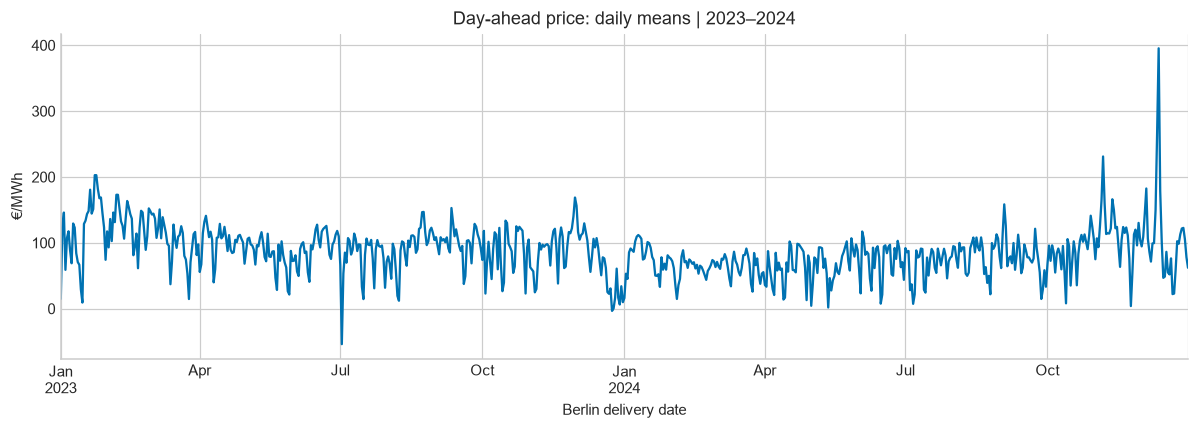

In [34]:
column = PRICE
fig, ax = plt.subplots()
df[column].tz_convert('Europe/Berlin').resample('D').mean().plot(ax=ax)
ax.set(title='Day-ahead price: daily means | 2023–2024', xlabel='Berlin delivery date', ylabel='€/MWh')
fig.tight_layout()
fig.savefig('source_covariates_day_ahead_price_time_plot.png', dpi=160, bbox_inches='tight')
plt.show()

#### Distribution

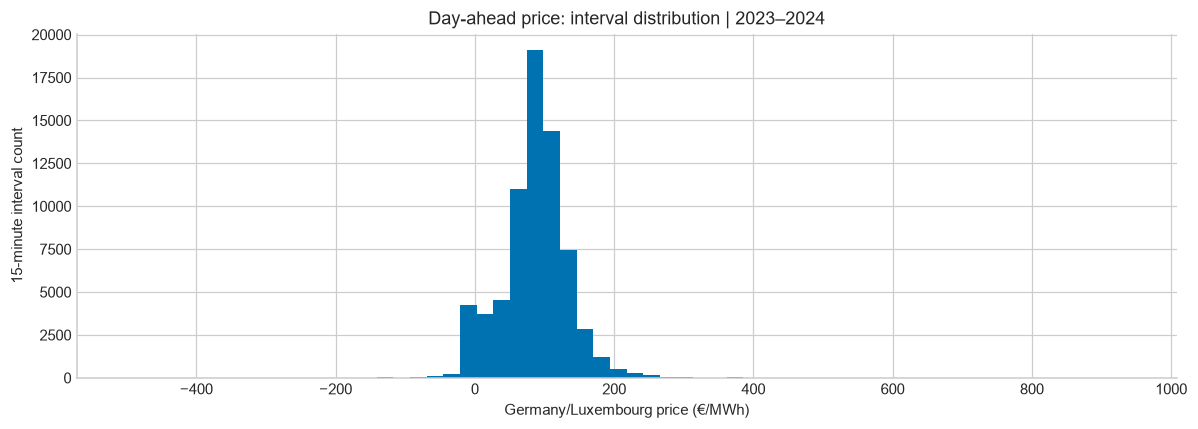

Negative-price intervals: 3,032. Repeated prices are counted at the aligned 15-minute resolution.


In [35]:
fig, ax = plt.subplots()
ax.hist(df[PRICE].dropna(), bins=60, color=COLORS[0])
ax.set(title='Day-ahead price: interval distribution | 2023–2024', xlabel='Germany/Luxembourg price (€/MWh)', ylabel='15-minute interval count')
fig.tight_layout()
fig.savefig('source_covariates_day_ahead_price_distribution.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Negative-price intervals: {df[PRICE].lt(0).sum():,}. Repeated prices are counted at the aligned 15-minute resolution.')

#### Relationship with residual load

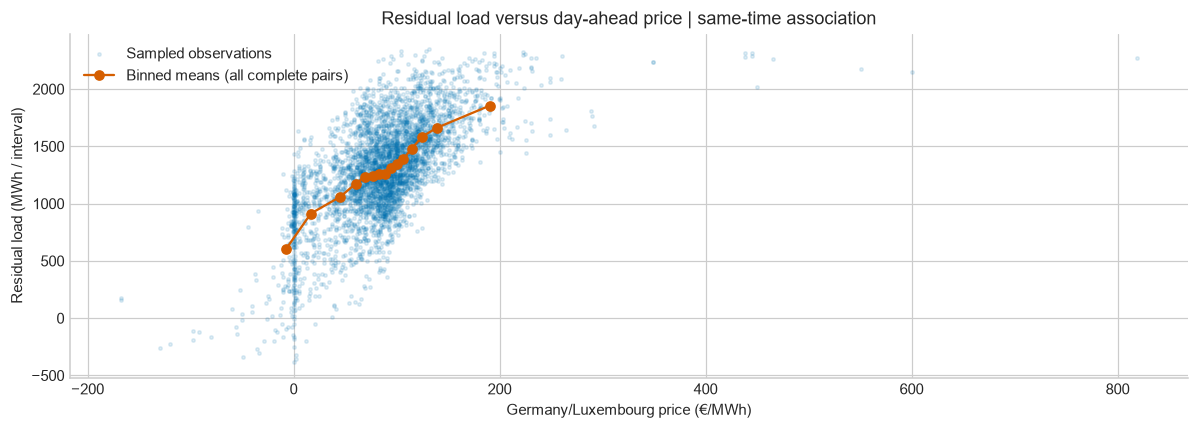

Complete pairs: 70,175. Pearson correlation: 0.642.


In [36]:
pairs = df[[PRICE, 'target']].dropna()
sample = pairs.sample(min(4000, len(pairs)), random_state=42)
bins = pd.qcut(pairs[PRICE], q=15, duplicates='drop')
binned = pairs.groupby(bins, observed=True).mean()
fig, ax = plt.subplots()
ax.scatter(sample[PRICE], sample['target'], s=5, alpha=.12, label='Sampled observations')
ax.plot(binned[PRICE], binned['target'], color=COLORS[1], marker='o', label='Binned means (all complete pairs)')
ax.set(title='Residual load versus day-ahead price | same-time association', xlabel='Germany/Luxembourg price (€/MWh)', ylabel='Residual load (MWh / interval)')
ax.legend()
fig.tight_layout()
fig.savefig('source_covariates_day_ahead_price_relationship.png', dpi=160, bbox_inches='tight')
plt.show()
print(f'Complete pairs: {len(pairs):,}. Pearson correlation: {pairs.corr().iloc[0, 1]:.3f}.')

#### Observations

Average day-ahead price falls from about €95/MWh in 2023 to €79/MWh in 2024. Despite the lower average, 2024 contains the highest price spike, reaching €936/MWh for an individual delivery interval. Negative prices occur in 4.32% of the aligned intervals.

Residual load generally increases with price, with correlation 0.642. The increasing binned curve is consistent with higher prices accompanying tighter supply relative to demand, although it does not establish causation. A few extreme prices lie far outside the central cloud, so the strength of the overall correlation does not imply a precise relationship at those extremes.

## 5. Numeric correlation heatmap

Correlations describe linear associations among residual load, load measurements, weather, and Germany/Luxembourg day-ahead price. Shared seasonal patterns and overlapping load measurements can contribute to these relationships. Available observation pairs are used, with four final intervals lacking aligned weather observations.

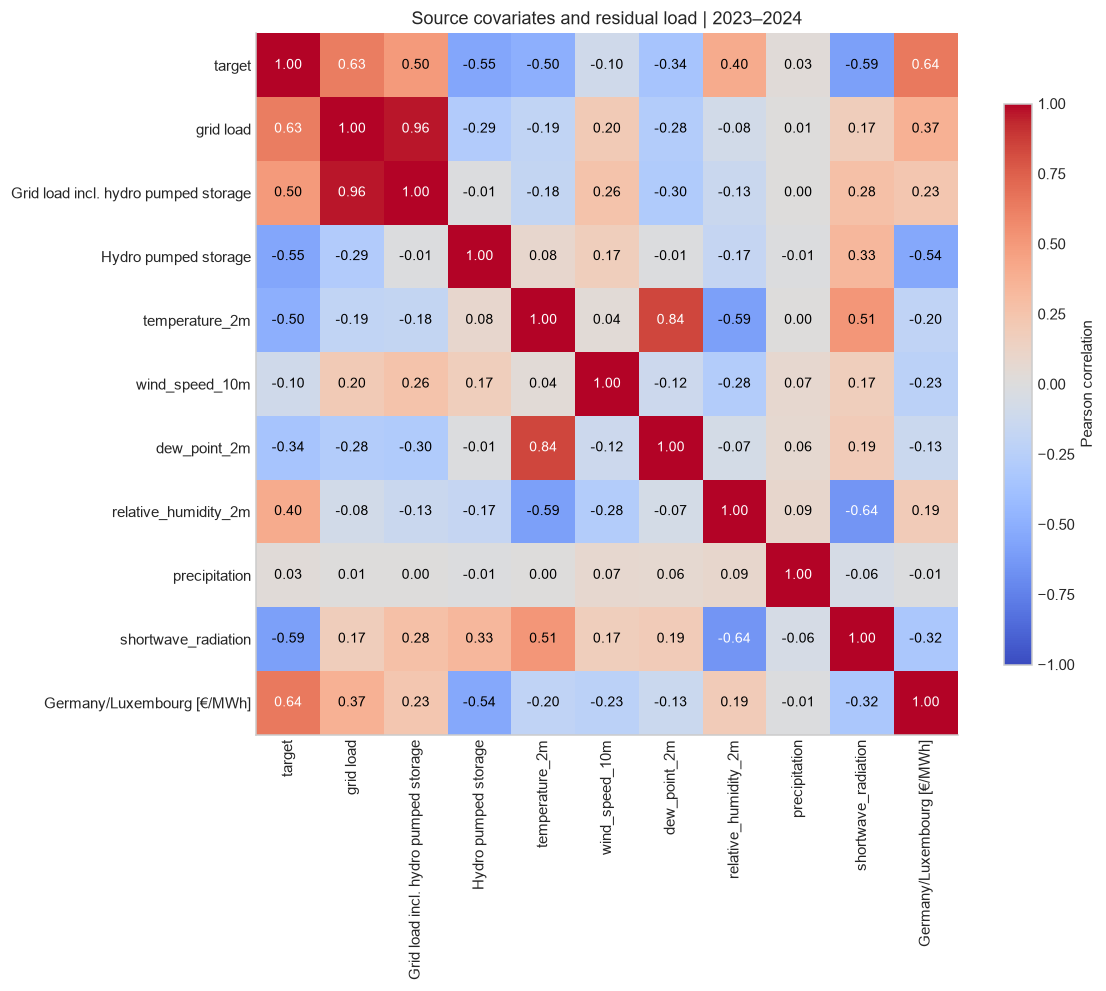

Pairwise complete observations. Shared seasonal patterns and overlapping load measures affect these associations.


In [37]:
columns = ['target', *selected_historical]
correlations = df[columns].corr()
# Use Source Labels
short_labels = [c.replace(' [MWh]', '').replace(' (°C)', '').replace(' (km/h)', '').replace(' (%)', '').replace(' (mm)', '').replace(' (W/m²)', '') for c in columns]
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(columns)), short_labels, rotation=90)
ax.set_yticks(range(len(columns)), short_labels)
ax.grid(False)
for row in range(len(columns)):
    for col in range(len(columns)):
        value = correlations.iloc[row, col]
        ax.text(col, row, f'{value:.2f}', ha='center', va='center', color='white' if abs(value) > .6 else 'black', fontsize=9)
fig.colorbar(image, ax=ax, label='Pearson correlation', shrink=.8)
ax.set_title('Source covariates and residual load | 2023–2024')
fig.tight_layout()
fig.savefig('numeric_correlation_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()
print('Pairwise complete observations. Shared seasonal patterns and overlapping load measures affect these associations.')

### Observations

Day-ahead price and grid load have the strongest positive target correlations, around 0.64 and 0.63. Radiation, pumped storage, and temperature have the clearest negative associations. Local wind speed and precipitation have weak pooled linear relationships, which leaves their conditional or lagged predictive value unresolved.

Several inputs overlap strongly. Grid load and inclusive load correlate at 0.96, while temperature and dew point correlate at 0.84. Humidity and radiation move in opposite directions at −0.64. These dependencies mean that separate pairwise associations cannot be added together or treated as evidence of independent model contributions.

## 6. Conclusions and modelling implications

Grid load, radiation, temperature, pumped storage, and day-ahead price show meaningful same-time relationships with residual load. Their patterns are consistent with residual load reflecting both electricity demand and variable renewable output, with price also describing wider market conditions. These relationships provide a basis for evaluating the selected inputs in forecasting.

Several covariates carry overlapping information. The three load columns have an exact arithmetic dependency, while temperature and dew point are strongly correlated. Their separate pairwise relationships therefore provide limited evidence of independent predictive contributions. Local wind speed and precipitation show weak pooled linear associations, leaving their conditional and lagged usefulness unresolved.

The forecasting value of each input depends on what is available at the forecast origin. Observed future load and weather require forecasts or suitably lagged observations, while day-ahead price requires publication before the relevant origin. Chronological validation can establish whether these available inputs improve on a target-history baseline, with any feature-group comparisons treated as separate experiments.